# Tasa de muones vs. ángulo polar

Para cada carpeta `grupo_7_jueves/medidas/polar_<ángulo>_deg` se leen los timestamps de los eventos seleccionados (todas las partes `idx*` de la corrida; si hay varias versiones `polar_<ángulo>_deg_vN` de un ángulo, se grafican todas pero solo la más nueva entra en el ajuste), se calculan los tiempos entre eventos consecutivos $\Delta t$ y se grafica la tasa

$$R(\theta) = \frac{1}{\langle \Delta t \rangle}$$

con incerteza $\sigma_R = \sigma_{\langle\Delta t\rangle} / \langle\Delta t\rangle^2$, donde $\sigma_{\langle\Delta t\rangle} = s_{\Delta t}/\sqrt{N}$.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

try:
    plt.style.use('seaborn-v0_8')
except Exception:
    plt.style.use('default')

plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 12,
    'axes.labelsize': 13,
    'axes.titlesize': 13,
    'legend.fontsize': 11,
    'legend.frameon': True,
})

DIR_MEDIDAS = Path('../grupo_7_jueves/medidas')

## Lectura de timestamps

In [2]:
_RE_EVENTO = re.compile(r'^Event #(\d+)\s+ts=(\S+ \S+)')


def leer_timestamps(carpeta):
    """Devuelve los timestamps (ordenados) de todos los eventos en los archivos de la carpeta."""
    ts = []
    for archivo in sorted(carpeta.glob('*.txt')):
        with open(archivo) as f:
            for linea in f:
                m = _RE_EVENTO.match(linea)
                if m:
                    ts.append(pd.Timestamp(m.group(2)))
    return pd.Series(sorted(set(ts)))


_RE_CARPETA = re.compile(r'polar_([\d.]+)_deg(?:_v(\d+))?$')

carpetas = []
for p in DIR_MEDIDAS.glob('polar_*_deg*'):
    m = _RE_CARPETA.match(p.name)
    if m:
        carpetas.append((float(m.group(1)), int(m.group(2) or 1), p))

filas = []
for angulo, version, carpeta in sorted(carpetas):
    ts = leer_timestamps(carpeta)
    dt = ts.diff().dropna().dt.total_seconds().to_numpy()
    n = len(dt)
    dt_medio = dt.mean()
    err_dt = dt.std(ddof=1) / np.sqrt(n)
    filas.append({
        'angulo_deg': angulo,
        'carpeta': carpeta.name,
        'version': version,
        'N_eventos': len(ts),
        'duracion_s': (ts.iloc[-1] - ts.iloc[0]).total_seconds(),
        'dt_medio_s': dt_medio,
        'err_dt_s': err_dt,
        'tasa_Hz': 1 / dt_medio,
        'err_tasa_Hz': err_dt / dt_medio**2,
    })

df = pd.DataFrame(filas)
# Solo la versión más nueva de cada ángulo (polar_X_deg_vN reemplaza a polar_X_deg) entra en el ajuste
df['en_ajuste'] = df['version'] == df.groupby('angulo_deg')['version'].transform('max')
df

,angulo_deg,carpeta,version,N_eventos,duracion_s,dt_medio_s,err_dt_s,tasa_Hz,err_tasa_Hz,en_ajuste
0,0.0,polar_0_deg,1,40,1773.360,45.470769,8.188129,0.021992,0.003960,True
1,15.0,polar_15_deg,1,22,1585.200,75.485714,16.850003,0.013248,0.002957,False
2,15.0,polar_15_deg_v2,2,26,1834.475,73.379000,16.107280,0.013628,0.002991,True
3,25.0,polar_25_deg,1,31,1748.712,58.290400,11.164996,0.017155,0.003286,True
4,35.0,polar_35_deg,1,25,1822.293,75.928875,14.881087,0.013170,0.002581,True
5,45.0,polar_45_deg,1,14,1827.143,140.549462,39.518238,0.007115,0.002001,True
6,56.0,polar_56_deg,1,7,1650.344,275.057333,81.096535,0.003636,0.001072,True


## Gráfico: $1/\langle\Delta t\rangle$ vs. ángulo

Se ajusta además $R(\theta) = R_0 \cos^n\theta$ (se espera $n \approx 2$) usando solo la medición más nueva de cada ángulo; las versiones anteriores se muestran con marcador hueco.

R0 = 1.17 ± 0.14 eventos/min
n  = 2.78 ± 0.50


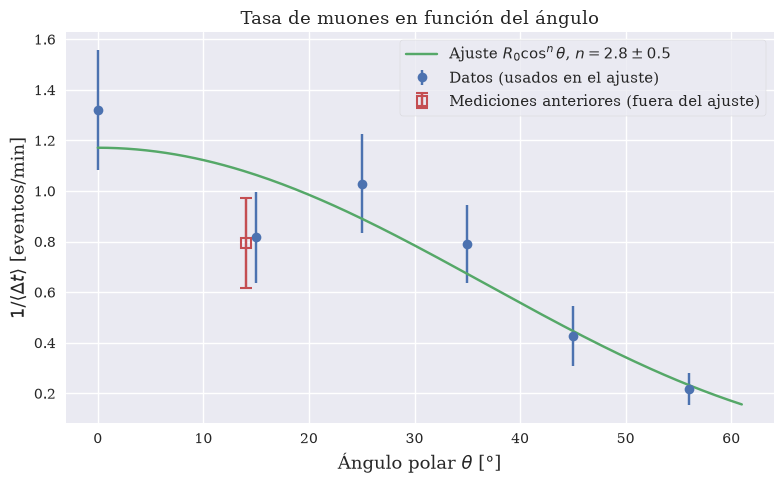

In [3]:
def modelo(theta_deg, R0, n):
    return R0 * np.cos(np.deg2rad(theta_deg))**n


df_ajuste = df[df['en_ajuste']]
df_viejas = df[~df['en_ajuste']]

popt, pcov = curve_fit(modelo, df_ajuste['angulo_deg'], df_ajuste['tasa_Hz'], sigma=df_ajuste['err_tasa_Hz'],
                       absolute_sigma=True, p0=[df_ajuste['tasa_Hz'].max(), 2])
perr = np.sqrt(np.diag(pcov))
print(f'R0 = {popt[0]*60:.2f} ± {perr[0]*60:.2f} eventos/min')
print(f'n  = {popt[1]:.2f} ± {perr[1]:.2f}')

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(df_ajuste['angulo_deg'], df_ajuste['tasa_Hz'] * 60, yerr=df_ajuste['err_tasa_Hz'] * 60,
            fmt='o', capsize=4, label='Datos (usados en el ajuste)')
if not df_viejas.empty:
    # Desplazadas 1° en x para que no queden tapadas por la medición nueva del mismo ángulo
    ax.errorbar(df_viejas['angulo_deg'] - 1, df_viejas['tasa_Hz'] * 60, yerr=df_viejas['err_tasa_Hz'] * 60,
                fmt='s', mfc='none', mew=1.5, ms=7, color='C2', capsize=4, zorder=3,
                label='Mediciones anteriores (fuera del ajuste)')
theta = np.linspace(0, df['angulo_deg'].max() + 5, 200)
ax.plot(theta, modelo(theta, *popt) * 60,
        label=rf'Ajuste $R_0\cos^n\theta$, $n={popt[1]:.1f}\pm{perr[1]:.1f}$')
ax.set_xlabel(r'Ángulo polar $\theta$ [°]')
ax.set_ylabel(r'$1/\langle\Delta t\rangle$ [eventos/min]')
ax.set_title('Tasa de muones en función del ángulo')
ax.legend()
plt.tight_layout()
plt.show()